# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:

# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / 1024**2                     # 16 bits = 2 bytes per voxel

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)         # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = 512 * 300 * 512                   # one ray per x-z pixel x 512 steps along y
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")


78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_ (1) **Shape distortion:** the voxels are twice as tall in z (1.0 mm) as they are wide (0.5 mm), so if the software drew each voxel as a square pixel, the coronal and sagittal views would be squashed along z (a round structure would look like a flattened ellipse, with the head looking too short). (2) **Wrong measurements:** any distance, diameter or area read off those views would be off by the same factor in z (the lesion would look half as tall as it is), and a radiologist or surgeon relying on the on-screen size would be misled. The software must scale the z axis by the voxel aspect ratio (here ASPECT = z spacing / in-plane spacing).

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

1 candidate component(s); largest has 431 voxels; centroid (z, y, x) = (28, 40, 41)


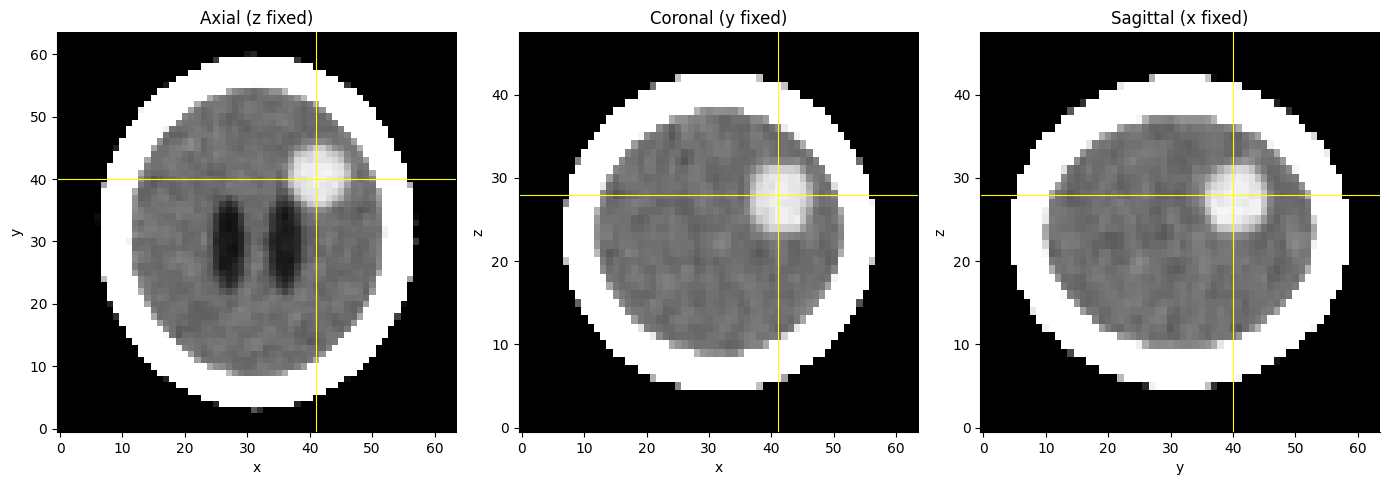

Centroid error vs ground truth: 2.92 mm (ground truth centroid z, y, x = [27.5 40.5 41.5])


In [3]:

def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: candidate lesion voxels (no labels used)
solid = vol > 300
inside = ndimage.binary_fill_holes(solid) & ~solid
inside = ndimage.binary_erosion(inside, iterations=3)           # drop the partial-volume shell under the skull
candidates = inside & (vol > 55) & (vol < 90)

# TODO 2: largest connected component and its centroid
cc, n_cc = ndimage.label(candidates)
sizes = ndimage.sum(candidates, cc, range(1, n_cc + 1))
lesion = cc == (np.argmax(sizes) + 1)
cz, cy, cx = [int(round(v)) for v in ndimage.center_of_mass(lesion)]
print(f"{n_cc} candidate component(s); largest has {int(sizes.max())} voxels; centroid (z, y, x) = ({cz}, {cy}, {cx})")

# TODO 3: axial / coronal / sagittal through the centroid, brain window W=80, L=40
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
views = [("Axial (z fixed)", vol[cz, :, :], (cx, cy), 1.0, "x", "y"),
         ("Coronal (y fixed)", vol[:, cy, :], (cx, cz), ASPECT, "x", "z"),
         ("Sagittal (x fixed)", vol[:, :, cx], (cy, cz), ASPECT, "y", "z")]
for ax, (title, sl, (px_, py_), asp, xl, yl) in zip(axes, views):
    ax.imshow(window(sl, 80, 40), cmap="gray", origin="lower", aspect=asp, vmin=0, vmax=1)
    ax.axvline(px_, color="yellow", lw=0.8); ax.axhline(py_, color="yellow", lw=0.8)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl)

plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
true_c = np.array(ndimage.center_of_mass(labels == 5))
err_mm = np.linalg.norm((np.array([cz, cy, cx]) - true_c) * np.array(SPACING))
print(f"Centroid error vs ground truth: {err_mm:.2f} mm (ground truth centroid z, y, x = {np.round(true_c, 1)})")


**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_ A voxel on the brain-skull boundary contains both brain (about 36 HU) and bone (several hundred HU), so through the **partial-volume effect** its measured value is an average and passes through intermediate values, including the 55-90 HU range of the tumour. That creates a thin shell of voxels just under the skull that match the tumour's intensity although they contain no tumour. This is the **overlapping intensity ranges** challenge (Slide 28): different materials (tumour and a brain/bone mixture) share the same HU values, so a threshold on intensity alone cannot tell them apart. Eroding the "inside the brain" mask by 3 voxels removes that shell, which is within a voxel or two of the bone, so only genuine interior voxels remain.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_mL,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


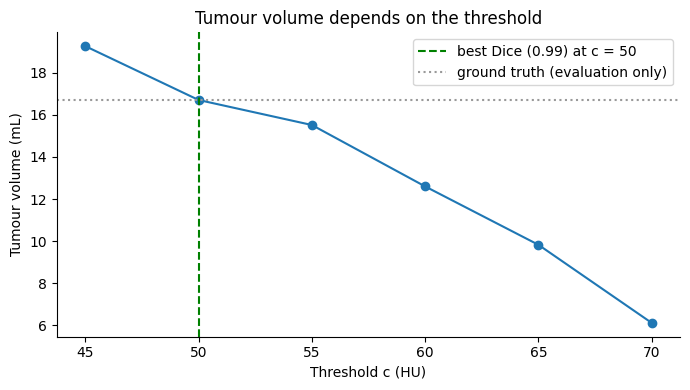

Volume range to report: 6.1 - 19.3 mL (best-Dice threshold c = 50 gives 16.7 mL; ground truth 16.7 mL)


In [4]:

truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    cc_, _ = ndimage.label(vol > c)
    region = cc_ == cc_[cz, cy, cx] if cc_[cz, cy, cx] > 0 else np.zeros_like(truth)
    n = int(region.sum())
    dice = 2 * (region & truth).sum() / (region.sum() + truth.sum()) if n else 0.0
    rows.append(dict(threshold=c, voxels=n, volume_mL=n * VOXEL_MM3 / 1000, dice=dice))

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold, table.volume_mL, "-o")
best = table.loc[table.dice.idxmax()]
ax.axvline(best.threshold, color="green", ls="--", label=f"best Dice ({best.dice:.2f}) at c = {int(best.threshold)}")
ax.axhline(truth.sum() * VOXEL_MM3 / 1000, color="0.6", ls=":", label="ground truth (evaluation only)")
ax.set_xlabel("Threshold c (HU)"); ax.set_ylabel("Tumour volume (mL)"); ax.set_title("Tumour volume depends on the threshold"); ax.legend()

plt.tight_layout(); plt.show()

# TODO 4
print(f"Volume range to report: {table.volume_mL.min():.1f} - {table.volume_mL.max():.1f} mL "
      f"(best-Dice threshold c = {int(best.threshold)} gives {best.volume_mL:.1f} mL; ground truth {truth.sum() * VOXEL_MM3 / 1000:.1f} mL)")


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_ Without labels I would pick c from the data: the tumour (about 66 HU) and the brain (about 36 HU) form two intensity populations, so a threshold about midway between them (around 50 HU) is a defensible, explainable choice, and I would check it against the slices by overlaying the c contour on the MPR views to confirm that it follows the visible edge. In this phantom that choice (c = 50) happens to match the ground truth (Dice 0.99, 16.7 mL), but the table shows the volume changes from 19.3 mL at c = 45 to 12.6 mL at c = 60 and 6.1 mL at c = 70, so I would not give the surgeon one number. I would report a range (roughly 12-19 mL for reasonable thresholds) and visualize the uncertainty: contours for several thresholds overlaid on the slices, nested semi-transparent isosurfaces, or a plot of volume versus threshold with the chosen value marked, so the surgeon sees how much the edge moves.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

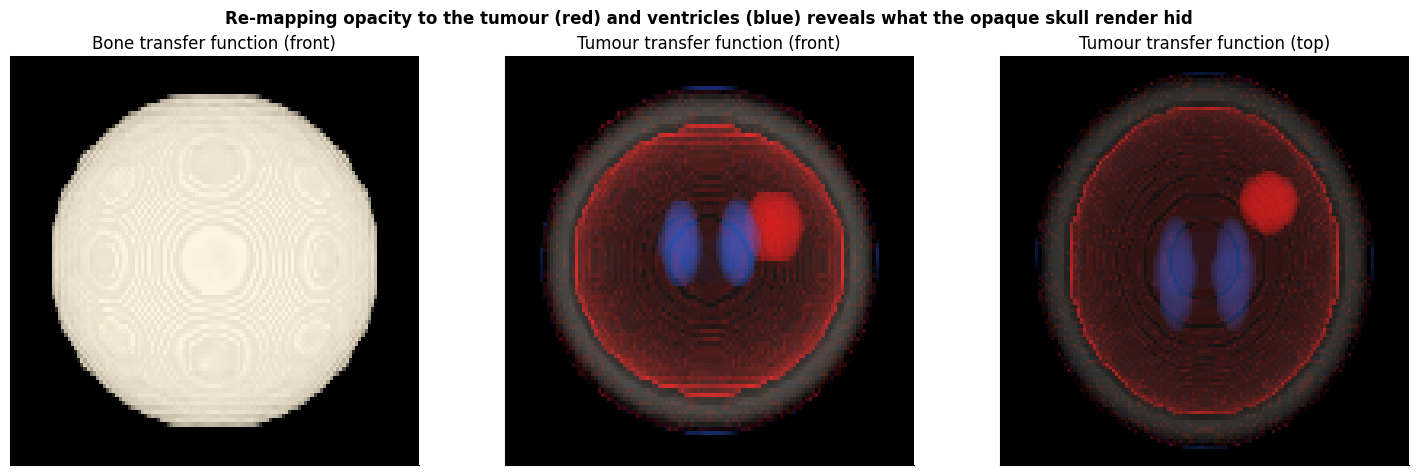

In [5]:

bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function (opacity is per sample and accumulates along each ray)
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),        # air: transparent
    (-20,   (0, 0, 0), 0.0),
    (0,     (0.2, 0.4, 1.0), 0.0),
    (5,     (0.2, 0.4, 1.0), 0.03),  # CSF (~5-20 HU): faint blue
    (20,    (0.2, 0.4, 1.0), 0.03),
    (28,    (0, 0, 0), 0.0),        # soft tissue / brain: transparent
    (50,    (0, 0, 0), 0.0),
    (56,    (1.0, 0.1, 0.1), 0.07),  # tumour range (~55-80 HU): red; kept low so thin shells stay faint
    (80,    (1.0, 0.1, 0.1), 0.07),
    (95,    (0, 0, 0), 0.0),
    (250,   (0, 0, 0), 0.0),
    (400,   (1, 0.95, 0.85), 0.005), # bone: almost transparent, just for context
    (1500,  (1, 1, 1), 0.01),
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
C_b, _ = render(vol, bone_tf, axis=1)
C_f, _ = render(vol, tumour_tf, axis=1)
C_t, _ = render(vol, tumour_tf, axis=0)
axes[0].imshow(np.clip(C_b, 0, 1), origin="lower", aspect=ASPECT); axes[0].set_title("Bone transfer function (front)")
axes[1].imshow(np.clip(C_f, 0, 1), origin="lower", aspect=ASPECT); axes[1].set_title("Tumour transfer function (front)")
axes[2].imshow(np.clip(C_t, 0, 1), origin="lower", aspect=1.0);   axes[2].set_title("Tumour transfer function (top)")
for ax in axes: ax.set_facecolor("black"); ax.set_xticks([]); ax.set_yticks([])

# TODO 4: suptitle
fig.suptitle("Re-mapping opacity to the tumour (red) and ventricles (blue) reveals what the opaque skull render hid", fontweight="bold")
plt.tight_layout(); plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_ The faint red rim comes from the **partial-volume effect and overlapping intensity ranges** (Slide 28): voxels at the brain-skull boundary take intermediate HU values that fall in the tumour's 55-80 HU range, so the transfer function colours them red even though they are not tumour. A **segmentation** step (Slides 31-32: segment/isolate the structure first, for example region growing from the lesion centre or masking to the eroded brain interior as in Task 2, and then render only that mask) would remove it. A transfer function alone cannot because it maps each voxel's intensity independently, and a boundary voxel with 65 HU looks identical to a real tumour voxel with 65 HU; telling them apart needs spatial context such as connectivity and position.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_ The lesion is a roughly round mass in the right, posterior part of the brain, a little above mid-height (voxel centre z = 28, y = 40, x = 41, about 3 mm from the true centre), with a volume of about 17 mL at the best threshold and roughly 12-19 mL for reasonable thresholds, so the number should be read as a range and not as an exact value. I would open the meeting with the **3-plane MPR with a segmentation overlay**, because slicing exposes the interior without occlusion, keeps the true geometry (aspect ratio corrected), and the segmentation is what makes the volume measurable. The 3-D render is best shown second, as context for how the tumour sits next to the ventricles. Its limitation is that it depends on the transfer function: opacity accumulates along each ray, intensity ranges overlap (the faint red rim under the skull is an artefact, not tissue) and the apparent size and colour change with the settings, so it should not be used for measurements.